# Part 3: Data Cleaning & Preprocessing
**Project:** Crop Recommendation System Using Machine Learning

This notebook cleans the Kaggle Crop Recommendation dataset and prepares it for modelling. Steps:
1. Load and inspect the data
2. Handle missing values
3. Handle duplicates
4. Check data types and validity ranges
5. Detect and decide how to treat outliers
6. Encode the target label
7. Split into training and test sets
8. Scale the features (fitted on training data only)
9. Save the outputs for Parts 4 to 9

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

RANDOM_STATE = 42          # fixed seed for reproducibility
sns.set_theme(style="whitegrid")
os.makedirs("outputs", exist_ok=True)

## 1. Load and inspect the data

In [2]:
CSV_PATH = "Crop_recommendation.csv"

# In Google Colab, upload the CSV if it is not already in the session
if not os.path.exists(CSV_PATH):
    try:
        from google.colab import files
        files.upload()
    except ImportError:
        raise FileNotFoundError(f"Place {CSV_PATH} in the same folder as this notebook.")

df = pd.read_csv(CSV_PATH)
print("Shape:", df.shape)
df.head()

Shape: (2200, 8)


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [3]:
df.info()
print()
print(df.describe().round(2))

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 137.6 KB

             N        P        K  temperature  humidity       ph  rainfall
count  2200.00  2200.00  2200.00      2200.00   2200.00  2200.00   2200.00
mean     50.55    53.36    48.15        25.62     71.48     6.47    103.46
std      36.92    32.99    50.65         5.06     22.26     0.77     54.96
min       0.00     5.00     5.00         8.83     14.26     3.50     20.21
25%      21.00    28.00    20.00        22.77    

## 2. Missing values
Missing values would break most scikit-learn models. We count them per column before deciding how to treat them.

In [4]:
missing = df.isnull().sum()
print(missing)
print("\nTotal missing values:", int(missing.sum()))

# Treatment (only runs if something is missing):
#  - numeric features: fill with the column median (robust to outliers)
#  - label: drop the row, because we cannot guess the target
num_cols = ["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]
if missing.sum() > 0:
    df = df.dropna(subset=["label"])
    df[num_cols] = df[num_cols].fillna(df[num_cols].median())
    print("Missing values handled. Remaining:", int(df.isnull().sum().sum()))
else:
    print("No missing values found, so no imputation is needed.")

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

Total missing values: 0
No missing values found, so no imputation is needed.


## 3. Duplicates
Duplicate rows can leak between the training and test sets and make accuracy look better than it is, so exact duplicates are removed.

In [5]:
n_dup = df.duplicated().sum()
print("Duplicate rows:", n_dup)
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Rows before: {before} | after: {len(df)}")

Duplicate rows: 0
Rows before: 2200 | after: 2200


## 4. Data types and validity checks
All seven inputs should be numeric and the label should be text. We also check the label for stray spaces or inconsistent capitalisation, and test that values fall within physically possible ranges.

In [6]:
# Make sure features are numeric (non-numeric entries become NaN so we can see them)
for c in num_cols:
    df[c] = pd.to_numeric(df[c], errors="coerce")
print("Non-numeric entries found:", int(df[num_cols].isnull().sum().sum()))

# Standardise the label text
df["label"] = df["label"].astype(str).str.strip().str.lower()
print("Number of crop classes:", df["label"].nunique())
print(df["label"].value_counts().to_string())

Non-numeric entries found: 0
Number of crop classes: 22
label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100


In [7]:
# Validity ranges (physically possible values)
checks = {
    "ph between 0 and 14":          df["ph"].between(0, 14),
    "humidity between 0 and 100":   df["humidity"].between(0, 100),
    "N, P, K are non-negative":     (df[["N", "P", "K"]] >= 0).all(axis=1),
    "rainfall is non-negative":     df["rainfall"] >= 0,
}
for name, ok in checks.items():
    print(f"{name:32s} -> invalid rows: {(~ok).sum()}")

ph between 0 and 14              -> invalid rows: 0
humidity between 0 and 100       -> invalid rows: 0
N, P, K are non-negative         -> invalid rows: 0
rainfall is non-negative         -> invalid rows: 0


## 5. Outliers
We use the IQR rule: a value is flagged if it lies below Q1 - 1.5 x IQR or above Q3 + 1.5 x IQR.

**Key point:** in this dataset each crop grows in a different range of conditions (for example, rice needs far more rainfall than chickpea). A value that looks extreme across the whole dataset may be perfectly normal for its own crop. So we check outliers twice: across all rows, and within each crop.

In [8]:
def iqr_bounds(s):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    return q1 - 1.5 * iqr, q3 + 1.5 * iqr

# (a) Across the whole dataset
rows = []
for c in num_cols:
    lo, hi = iqr_bounds(df[c])
    rows.append({"feature": c, "lower": round(lo, 2), "upper": round(hi, 2),
                 "outliers": int(((df[c] < lo) | (df[c] > hi)).sum())})
overall = pd.DataFrame(rows)
print(overall.to_string(index=False))

    feature  lower  upper  outliers
          N -73.88 179.12         0
          P -32.00 128.00       138
          K -23.50  92.50       200
temperature  14.08  37.25        86
   humidity  15.73 134.48        30
         ph   4.54   8.35        57
   rainfall -25.02 213.84       100


In [9]:
# (b) Within each crop: values that are unusual even for their own crop
within = pd.Series(False, index=df.index)
for crop, g in df.groupby("label"):
    for c in num_cols:
        lo, hi = iqr_bounds(g[c])
        within.loc[g.index] |= (g[c] < lo) | (g[c] > hi)

print("Rows flagged across the whole dataset:",
      int(pd.concat([(df[c] < iqr_bounds(df[c])[0]) | (df[c] > iqr_bounds(df[c])[1]) for c in num_cols], axis=1).any(axis=1).sum()))
print("Rows flagged within their own crop:   ", int(within.sum()))

Rows flagged across the whole dataset: 432
Rows flagged within their own crop:    0


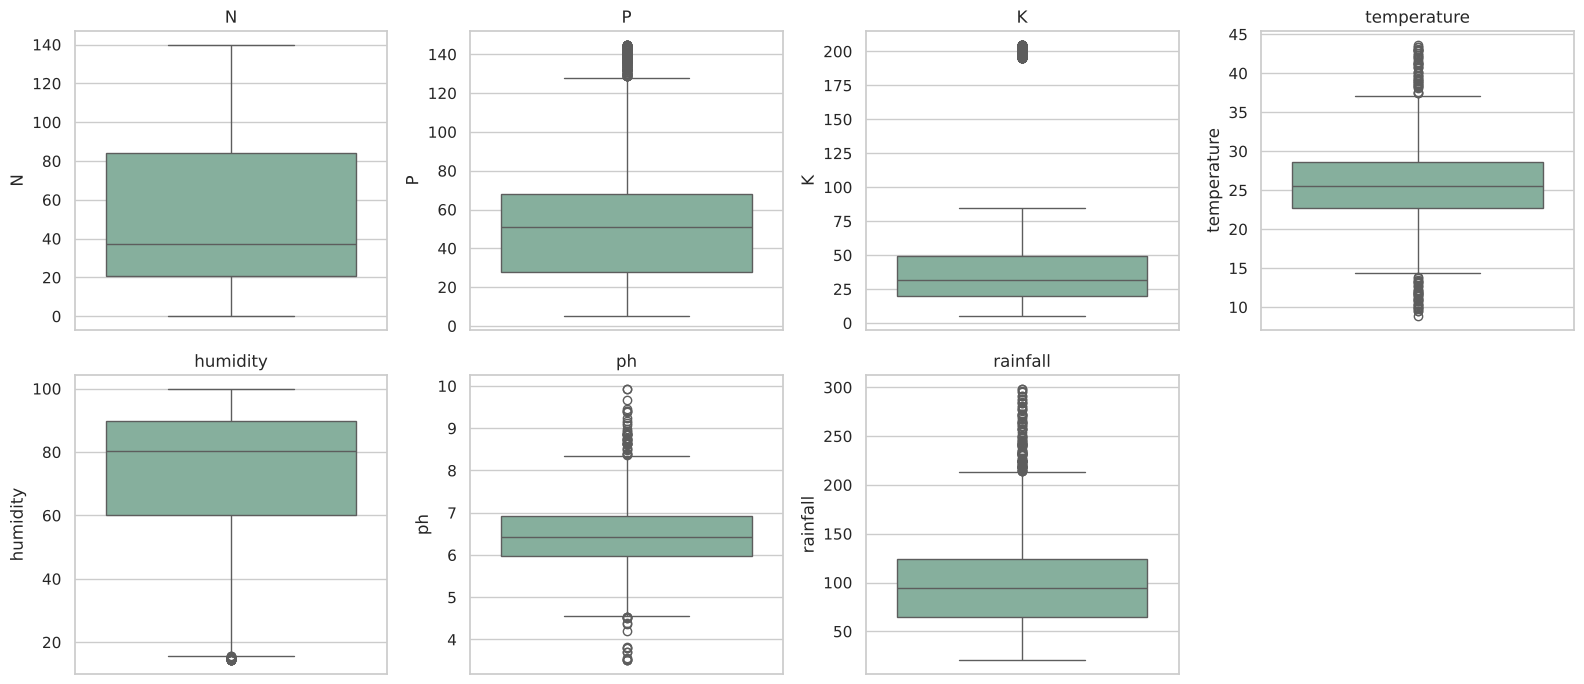

In [10]:
# Visualise the spread of each feature
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, c in zip(axes.ravel(), num_cols):
    sns.boxplot(y=df[c], ax=ax, color="#7fb69e")
    ax.set_title(c)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig("outputs/boxplots_outliers.png", dpi=150)
plt.show()

**Decision: outliers are kept, not removed.**
- Many values flagged across the whole dataset belong to one specific crop (e.g. high rainfall for rice, high potassium for grapes and apple). They are real signal, not errors.
- The validity checks in step 4 found no impossible values, so there is no evidence of data-entry errors.
- Removing them would delete records of particular crops and could make those crops harder to recognise.
- The tree-based models we plan to use (Decision Tree, Random Forest) are not sensitive to outliers.

**Result on the real dataset:** 432 rows are flagged when the whole dataset is considered, but **0 rows** are flagged within their own crop. All the "outliers" are therefore normal values for a particular crop (for example, high K for grapes and apple, and high rainfall for rice), which confirms that they should be kept.

## 6. Encode the target label
Models need numbers, not crop names. `LabelEncoder` maps each crop to an integer. All seven inputs are already numeric, so no encoding of features is needed. The encoder is saved so the Flask app can convert predictions back into crop names.

In [11]:
X = df[num_cols].copy()
le = LabelEncoder()
y = le.fit_transform(df["label"])

mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(mapping)
joblib.dump(le, "outputs/label_encoder.pkl")

{'apple': np.int64(0), 'banana': np.int64(1), 'blackgram': np.int64(2), 'chickpea': np.int64(3), 'coconut': np.int64(4), 'coffee': np.int64(5), 'cotton': np.int64(6), 'grapes': np.int64(7), 'jute': np.int64(8), 'kidneybeans': np.int64(9), 'lentil': np.int64(10), 'maize': np.int64(11), 'mango': np.int64(12), 'mothbeans': np.int64(13), 'mungbean': np.int64(14), 'muskmelon': np.int64(15), 'orange': np.int64(16), 'papaya': np.int64(17), 'pigeonpeas': np.int64(18), 'pomegranate': np.int64(19), 'rice': np.int64(20), 'watermelon': np.int64(21)}


['outputs/label_encoder.pkl']

## 7. Train / test split
We keep 80% for training and 20% for testing. `stratify=y` keeps the same share of each crop in both sets, and `random_state` makes the split repeatable. The split is done **before** scaling so that no information from the test set influences preprocessing (this avoids data leakage).

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

# Confirm both sets contain all crops in similar proportions
check = pd.DataFrame({
    "train_%": pd.Series(y_train).value_counts(normalize=True).sort_index() * 100,
    "test_%":  pd.Series(y_test).value_counts(normalize=True).sort_index() * 100,
}).round(2)
check.index = le.inverse_transform(check.index)
check.head(10)

Train: (1760, 7) | Test: (440, 7)


,train_%,test_%
apple,4.55,4.55
banana,4.55,4.55
blackgram,4.55,4.55
chickpea,4.55,4.55
coconut,4.55,4.55
coffee,4.55,4.55
cotton,4.55,4.55
grapes,4.55,4.55
jute,4.55,4.55
kidneybeans,4.55,4.55


## 8. Feature scaling
The seven features are on very different scales (rainfall is in the hundreds, pH is around 6 to 7). Distance- and gradient-based models such as KNN, SVM and Logistic Regression need features on a similar scale. `StandardScaler` rescales each feature to mean 0 and standard deviation 1.

The scaler is **fitted on the training set only**, then applied to both sets. Tree-based models do not need scaling, so we keep the unscaled data as well.

In [13]:
scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train), columns=num_cols, index=X_train.index)
X_test_scaled  = pd.DataFrame(scaler.transform(X_test),      columns=num_cols, index=X_test.index)

print("Scaled training means (should be about 0):")
print(X_train_scaled.mean().round(3).to_string())
print("\nScaled training std (should be about 1):")
print(X_train_scaled.std().round(3).to_string())
joblib.dump(scaler, "outputs/scaler.pkl")

Scaled training means (should be about 0):
N              0.0
P              0.0
K              0.0
temperature   -0.0
humidity      -0.0
ph            -0.0
rainfall       0.0

Scaled training std (should be about 1):
N              1.0
P              1.0
K              1.0
temperature    1.0
humidity       1.0
ph             1.0
rainfall       1.0


['outputs/scaler.pkl']

## 9. Save the cleaned data and splits for the next parts

In [14]:
df.to_csv("outputs/crop_clean.csv", index=False)
X_train.assign(label=y_train).to_csv("outputs/train_unscaled.csv", index=False)
X_test.assign(label=y_test).to_csv("outputs/test_unscaled.csv", index=False)
X_train_scaled.assign(label=y_train).to_csv("outputs/train_scaled.csv", index=False)
X_test_scaled.assign(label=y_test).to_csv("outputs/test_scaled.csv", index=False)

print(sorted(os.listdir("outputs")))

['boxplots_outliers.png', 'crop_clean.csv', 'label_encoder.pkl', 'scaler.pkl', 'test_scaled.csv', 'test_unscaled.csv', 'train_scaled.csv', 'train_unscaled.csv']


## Summary of cleaning steps
| Step | What we did | Result |
|---|---|---|
| Missing values | Counted per column; median fill / row drop only if needed | 0 missing values, no imputation needed |
| Duplicates | `drop_duplicates()` | 0 duplicate rows (2,200 rows kept) |
| Data types | Features converted to numeric; label trimmed and lower-cased | All 7 features numeric (3 int, 4 float); 22 crop classes, 100 records each |
| Validity | Checked pH, humidity, N/P/K and rainfall ranges | 0 invalid rows |
| Outliers | IQR rule, overall and within each crop | 432 rows flagged overall, 0 within their own crop; kept |
| Encoding | `LabelEncoder` on the crop label | 22 integer classes |
| Split | 80/20, stratified, seed 42 | Train 1,760 / Test 440 |
| Scaling | `StandardScaler` fitted on train only | Mean about 0, std about 1 |